In [1]:
#Все необходимые библиотеки
import pandas as pd
import os
import numpy as np
import cv2
from PIL import Image
import copy

import torch
import torch.nn as nn
import torch.optim as optim
import torch as th

import torchvision
from torchvision import datasets, models
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

from skimage.io import imread
from torch.utils import data
from tqdm import tqdm

import glob
import re

import time

from sklearn.metrics import confusion_matrix
import seaborn as sns

from torchmetrics.classification import MulticlassSpecificity
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import matthews_corrcoef

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Класс для создания общего датасета с метаданными
class CombineDataset(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, is_aug):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.is_aug = is_aug
        
        if self.is_aug == 1:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.RandomHorizontalFlip(),
                    transforms.RandomRotation(degrees=60),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        else:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
            
            

    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img_name = self.frame[self.id_col].iloc[idx]
        img = os.path.join (self.path_imgs, img_name +'.jpg')

        image1 = Image.open(img)
        image = self.aug(image1)

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return image, feats, label, name
    
class CombineDataset_cache(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, use_cache = False):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.inputs_dtype = torch.float32
        
        self.transform = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        
        self.use_cache = use_cache
        
        if self.use_cache:
            self.cached_data = []

            progressbar = tqdm(range(len(self.path_imgs)), desc='Caching')
            
            for i, img in zip(progressbar, self.path_imgs):
                img = Image.open(img)
                img= self.transform(img)                
                self.cached_data.append(img)
            
    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img = self.cached_data[idx]

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return img, feats, label, name
    
    
    # Определение процессора для обучения 
def get_default_device():
    if torch.cuda.is_available():
        
        return torch.device('cuda')
    else:
        return torch.device('cpu')

In [3]:
#Класс для выведения индексов для разделения базы изображений
class Sampler(object):
    def __init__(self, data_source):
        pass
    
    def __iter__(self):
        raise NotImplementedError
        
    def __len__(self):
        raise NotImplementedError
        
class StratifiedSampler(Sampler):
    
    def __init__(self, class_vector, z):
        self.n_splits = 1
        self.class_vector = class_vector
        self.test_size = z

    def gen_sample_array(self):
        try:
            from sklearn.model_selection import StratifiedShuffleSplit
        except:
             print('Ошибка распределения изображений')
        import numpy as np
        
        s = StratifiedShuffleSplit(n_splits=self.n_splits, test_size=self.test_size)
        X = th.randn(self.class_vector.size(0),2).numpy()
        y = self.class_vector.numpy()
        s.get_n_splits(X, y)

        train_index, test_index= next(s.split(X, y))
        return train_index, test_index

    def __iter__(self):
        return iter(self.gen_sample_array())

    def __len__(self):
        return len(self.class_vector)

In [5]:
data_dir = "C:\\Users\\Ulyana\\Мой диск (ulaliakhova@gmail.com)\\Базы изображений\\CLEAN DATASET\\"
metadata = pd.read_csv('C:\\Users\\Ulyana\\Мой диск (ulaliakhova@gmail.com)\\Базы изображений\\MetaData2.csv')

numbers = re.compile(r'(\d+)')
def numericalSort(value):
    parts = numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts

data_dir2 = sorted(glob.glob('C:\\Users\\Ulyana\\Мой диск (ulaliakhova@gmail.com)\\Базы изображений\\CLEAN DATASET\\*.jpg'), key=numericalSort)

labels_cat = ['0. vascular lesions', '1. nevus', '2. solar lentigo', '3. dermatofibroma', '4. seborrheic ketarosis', '5. benign ketarosis', '6. actinic keratosis', '7. basal cell carcinoma', '8. squamous cell carcinoma', '9. melanoma']
labels_cat2 = ['vascular lesions', 'nevus', 'solar lentigo', 'dermatofibroma', 'seborrheic ketarosis', 'benign ketarosis', 'actinic keratosis', 'basal cell carcinoma', 'squamous cell carcinoma', 'melanoma']

img_size = 227
num_classes = 10
num_epochs = 10

#CPU или GPU
device = get_default_device()
device

device(type='cuda')

In [6]:
#Кодируем метаданные

metadata_age = metadata[['age']]
Age_grup = []

for i in metadata_age['age']:
    if i <= 44:
        Age_grup += ['young']
        #print('молодой')
    elif 45 <= i <= 59:
        Age_grup += ['middle']
        #print('средний')
    elif 60 <= i <= 74:
        Age_grup += ['elderly']
        #print('пожилой')
    elif 75 <= i:
        Age_grup += ['senile']
        #print('долгожители')
    else:
        Age_grup += ['error']
        #print('ошибка')
        
metadata['age'] = Age_grup

In [7]:
#Кодируем метаданные

encode_map_categor = {'0. vascular lesions': 0, '1. nevus': 1, '2. solar lentigo': 2, '3. dermatofibroma': 3, '4. seborrheic ketarosis': 4, '5. benign ketarosis': 5, '6. actinic keratosis': 6, '7. basal cell carcinoma': 7, '8. squamous cell carcinoma': 8, '9. melanoma': 9}

encode_map_age = {'young': 0, 'middle': 1, 'elderly': 2, 'senile': 3}
encode_map_sex = {'male': 0, 'female': 1}
encode_map_anatomloc = {'anterior torso': 0, 'head/neck': 1, 'lateral torso': 2, 'lower extremity': 3, 'oral/genital': 4, 'palms/soles': 5, 'posterior torso': 6, 'upper extremity': 7}

#encode_map_age = {'young': '0001', 'middle': '0010', 'elderly': '0100', 'senile': '1000'}
#encode_map_sex = {'male': '01', 'female': '10'}
#encode_map_anatomloc = {'anterior torso': '00000001', 'head/neck': '00000010', 'lateral torso': '00000100', 'lower extremity': '00001000', 'oral/genital': '00010000', 'palms/soles': '00100000', 'posterior torso': '01000000', 'upper extremity': '10000000'}

metadata['diagnosis'].replace(encode_map_categor, inplace=True)
metadata['age'].replace(encode_map_age, inplace=True)
metadata['sex'].replace(encode_map_sex, inplace=True)
metadata['anatomloc'].replace(encode_map_anatomloc, inplace=True)

metadata['diagnosis'] = np.array(metadata['diagnosis'], dtype=np.int32)
metadata['age'] = np.array(metadata['age'], dtype=np.int32)
metadata['sex'] = np.array(metadata['sex'], dtype=np.int32)
metadata['anatomloc'] = np.array(metadata['anatomloc'], dtype=np.int32)

C:\Users\Ulyana\AppData\Local\Temp\ipykernel_15512\1033980212.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  metadata['diagnosis'].replace(encode_map_categor, inplace=True)
C:\Users\Ulyana\AppData\Local\Temp\ipykernel_15512\1033980212.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  metada

In [8]:
#Определяем индексы для разделения базы изображений

test_size = 0.2
valid_size = 0.25

data_label = metadata['diagnosis'].to_numpy()

ss = StratifiedSampler(torch.FloatTensor(data_label), test_size)
pre_train_indices, test_indices = ss.gen_sample_array()

train_label = np.delete(data_label, test_indices, None)
ss = StratifiedSampler(torch.FloatTensor(train_label), valid_size)
train_indices, val_indices = ss.gen_sample_array()

indices = {'train': pre_train_indices[train_indices],
           'val': pre_train_indices[val_indices],
           'test': test_indices
           }

train_indices = indices['train']
val_indices = indices['val']
test_indices = indices['test']

#Выводим индексы для разделения базы изображений

print("Размер тренировочной базы:", len(train_indices))
print("Размер валидационной базы:", len(val_indices))
print("Размер тестовой базы:", len(test_indices))

#torch.save(train_indices, 'Parametr\\train_indices.pt')
#torch.save(val_indices, 'Parametr\\val_indices.pt')
#torch.save(test_indices, 'Parametr\\test_indices.pt')

train_indices = torch.load('Parametr\\train_indices.pt', weights_only=False)
val_indices = torch.load('Parametr\\val_indices.pt', weights_only=False)
test_indices = torch.load('Parametr\\test_indices.pt', weights_only=False)

Размер тренировочной базы: 25035
Размер валидационной базы: 8345
Размер тестовой базы: 8345


In [9]:
len_valset = len(val_indices)
len_trainset = len(train_indices)

In [10]:
#Функция для получения веса для каждой категории
def estimate_weights_mfb(label):
    class_weights = np.zeros_like(label, dtype=float)
    counts = np.zeros_like(label)
    for i,l in enumerate(label):
        m = metadata['diagnosis'].value_counts()
        counts[i] = m[i]
    counts = counts.astype(float)
    median_freq = np.median(counts)
    
    for i, label in enumerate(label):
        class_weights[i] = median_freq / counts[i]
    return class_weights

weight = estimate_weights_mfb(labels_cat)
weight = torch.FloatTensor(weight).to(device)

for i in range(len(labels_cat)):
    print(labels_cat[i],":", weight[i])

0. vascular lesions : tensor(3.8893, device='cuda:0')
1. nevus : tensor(0.0353, device='cuda:0')
2. solar lentigo : tensor(3.6444, device='cuda:0')
3. dermatofibroma : tensor(4., device='cuda:0')
4. seborrheic ketarosis : tensor(0.6721, device='cuda:0')
5. benign ketarosis : tensor(0.8954, device='cuda:0')
6. actinic keratosis : tensor(1.1323, device='cuda:0')
7. basal cell carcinoma : tensor(0.2900, device='cuda:0')
8. squamous cell carcinoma : tensor(1.5000, device='cuda:0')
9. melanoma : tensor(0.1758, device='cuda:0')


In [11]:
Data_set = CombineDataset_cache(metadata, 'name', 'diagnosis', data_dir2, use_cache = True)

Caching: 100%|██████████████████████████████████████████████████████████████████| 41725/41725 [02:05<00:00, 333.63it/s]


In [12]:
batch_size = 64

trainloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = train_indices)
valloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = val_indices)
testloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = test_indices)

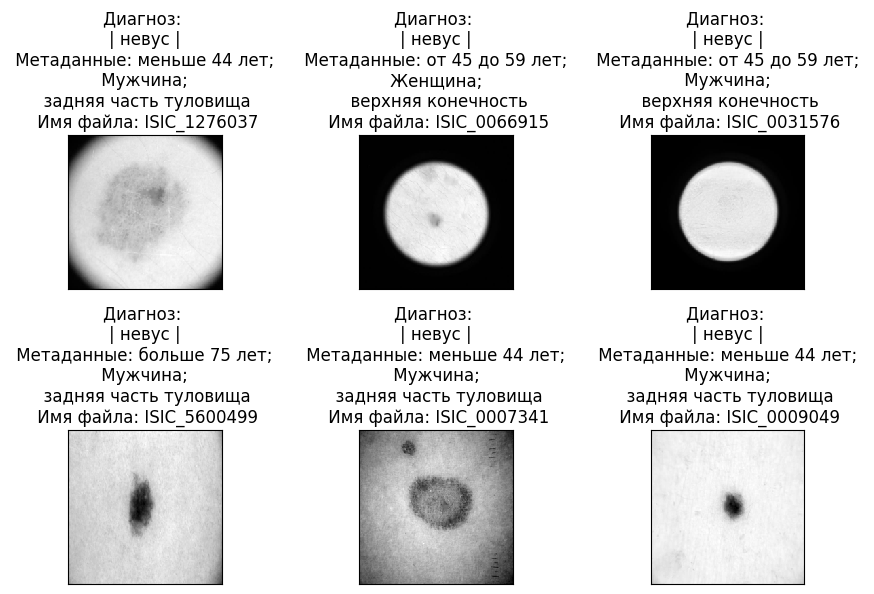

In [13]:
age = ['меньше 44 лет', 'от 45 до 59 лет', 'от 60 до 74 лет', 'больше 75 лет']
sex = ['Мужчина', 'Женщина']
anatomloc = ['торс', 'голова/шея', 'боковая часть туловища', 'нижняя конечность', 'оральная/генитальная зона', 'ладони/подошвы', 'задняя часть туловища', 'верхняя конечность']
lab = ['сосудистое поражение', 'невус', 'солнечное лентиго', 'дерматофиброма', 'себорейный кератоз', 'доброкачественный кератоз', 'актинический кератоз', 'базально-клеточная карцинома', 'плоскоклеточный рак', 'меланома']


examples = enumerate(trainloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

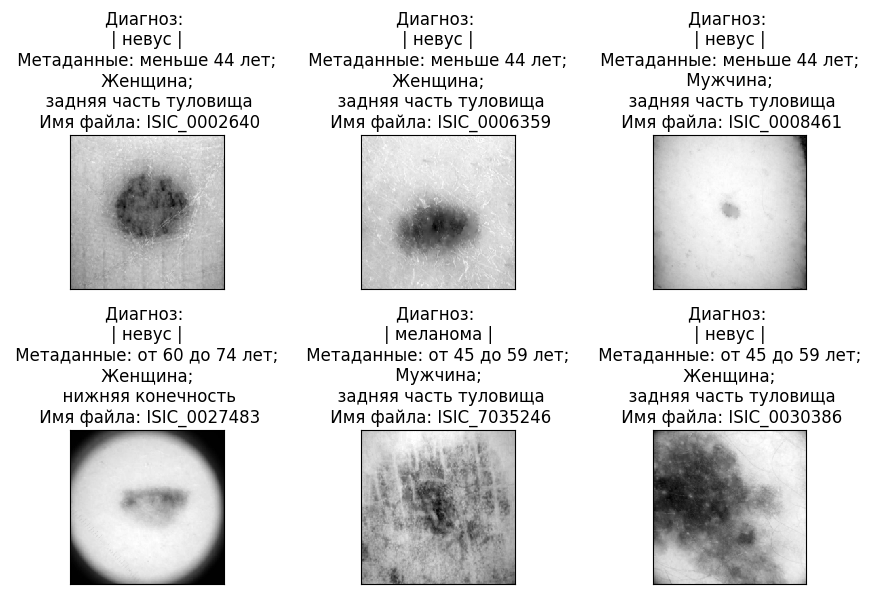

In [14]:
examples = enumerate(valloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

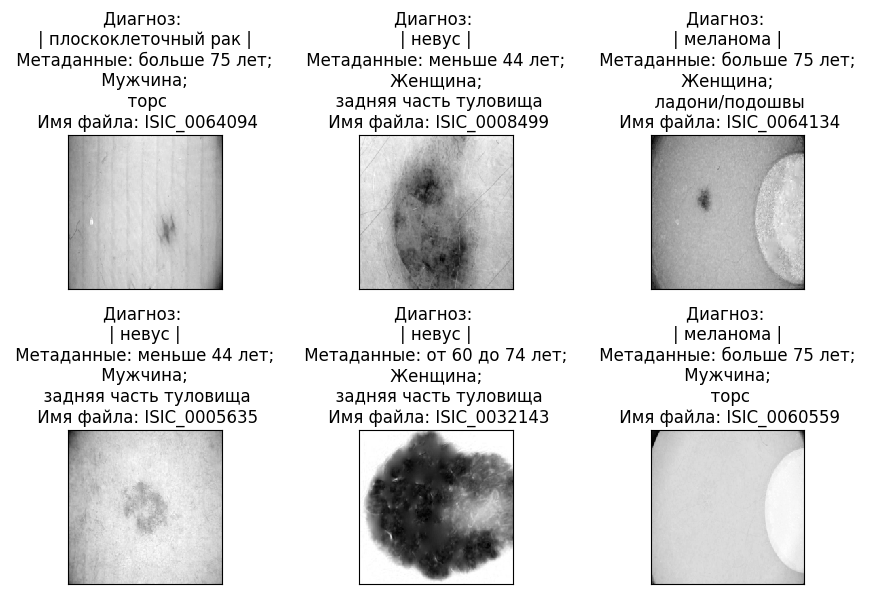

In [15]:
examples = enumerate(testloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

In [16]:
import timm

inception_v4 = timm.create_model('inception_v4', pretrained=True)
inception_v4.last_linear = nn.Linear(in_features=1536, out_features=num_classes)


class Classification_M(nn.Module):
    def __init__(self):
        super(Classification_M, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_M = Classification_M()    
    
class MultimodalNN(nn.Module):
    def __init__(self):
        super(MultimodalNN, self).__init__()
        
        self.CNN = inception_v4
       
        self.meta_net = Classification_M
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

NET_deep = MultimodalNN()

model_name = 'inception_v4_Yogi.pt'
model_weights = torch.load(model_name, device)
NET_deep.load_state_dict(model_weights)
NET_deep = NET_deep.to(device)

NET_deep

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Ulyana\.cache\huggingface\hub\models--timm--inception_v4.tf_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


MultimodalNN(
  (CNN): InceptionV4(
    (features): Sequential(
      (0): ConvNormAct(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
        (bn): BatchNormAct2d(
          32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): ReLU(inplace=True)
        )
      )
      (1): ConvNormAct(
        (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
        (bn): BatchNormAct2d(
          32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): ReLU(inplace=True)
        )
      )
      (2): ConvNormAct(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn): BatchNormAct2d(
          64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): ReLU(inplace=True)
        )
      )
      (3): Mixed3a(
        (maxpool): MaxPoo

In [17]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
nn_light = MultimodalNN_light().to(device)

torch.manual_seed(42)
new_nn_light = MultimodalNN_light().to(device)

#model_name = 'Parametr\\nn_light_2.pt'
#torch.save(nn_light.state_dict(), model_name)

nn_light

MultimodalNN_light(
  (CNN): Net(
    (layer1): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=128, out_features=32, bias=True)
    (fc2): Linear(in_features=32, out_features=10, bias=True)
  )
  (meta_net): Classification_MM(
    (layer_1): Linear(in_features=3, out_features=64, bias=True)
    (relu1): ReLU()
  

In [18]:
#print("Норма 1-го слоя в nn_deep:", torch.norm(nn_deep.features[0].weight).item())
#print("Норма 1-го слоя в  nn_light:", torch.norm(nn_light.features[0].weight).item())
#print("Норма 1-го слоя в  new_nn_light:", torch.norm(new_nn_light.features[0].weight).item())

In [19]:
total_params_deep = "{:,}".format(sum(p.numel() for p in NET_deep.parameters()))
print(f"nn_deep параметры: {total_params_deep}")
total_params_light = "{:,}".format(sum(p.numel() for p in nn_light.parameters()))
print(f"nn_light параметры: {total_params_light}")
total_params_light = "{:,}".format(sum(p.numel() for p in new_nn_light.parameters()))
print(f"new_nn_light параметры: {total_params_light}")

nn_deep параметры: 41,161,254
nn_light параметры: 267,686
new_nn_light параметры: 267,686


In [20]:
def test(model, dataset, device):

    start_time_glob = time.time()
    model.to(device)
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for i, data in enumerate(dataset):
            inputs, feats, labels, name = data
            inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)

            outputs = model(inputs, feats)
            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    
    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
    
    return accuracy

def test_NN(model, dataset):

    start_time_glob = time.time()
    model.eval()
    
    with torch.no_grad():
        for data in dataset:
            image, feats, label, name = data
            image, feats, label = image.to(device), feats.to(device), label.to(device)

            output = model(image, feats)

            pred = (torch.max(torch.exp(output), 1)[1]).cpu().data.numpy()

            predictions.extend(pred)

            label = label.cpu().data.numpy()
            actuals.extend(label)

    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
        
def test_metric():
    
    cm = confusion_matrix(actuals, predictions)
    FP = np.mean(cm.sum(axis=0) - np.diag(cm))  
    FN = np.mean(cm.sum(axis=1) - np.diag(cm))
    TP = np.mean(np.diag(cm))
    TN = np.mean(cm.sum() - (FP + FN + TP))

    Sensitivity = (TP/(TP+FN))
    Specificity = (TN/(TN+FP))
    Precision = (TP/(TP+FP))
    NPV = (TN/(TN+FN))
    PPV = (TP/(TP+FP))
    FNR = (FN/(FN+TP))
    FPR = (FP/(FP+TN))

    F1 = (2*TP)/((2*TP)+FP+FN) 

    recall_1 = recall_score(actuals, predictions, average='micro')
    recall_2 = recall_score(actuals, predictions, average='macro')
    

    precision_1 = precision_score(actuals, predictions, average='micro')
    precision_2 = precision_score(actuals, predictions, average='macro')


    f1_1 = f1_score(actuals, predictions, average='micro')
    f1_2 = f1_score(actuals, predictions, average='macro')
    
    jaccard_1 = jaccard_score(actuals, predictions, average='micro')
    jaccard_2 = jaccard_score(actuals, predictions, average='macro')

    accuracy_1 = accuracy_score(actuals, predictions)

    MCC = matthews_corrcoef(actuals, predictions)

    pre = torch.tensor(predictions)
    ac = torch.tensor(actuals)

    specificity1 = MulticlassSpecificity(average='macro', num_classes=10)
    s1 = specificity1(pre, ac)

    specificity2 = MulticlassSpecificity(average='micro', num_classes=10)
    s2 = specificity2(pre, ac)

    specificity3 = MulticlassSpecificity(average='weighted', num_classes=10)
    s3 = specificity3(pre, ac)

    specificity4 = MulticlassSpecificity(average='none', num_classes=10)
    s4 = specificity4(pre, ac)
    
    print('_' * 60)
    print('Accuracy score: %.4f' % accuracy_1*100)
    print('Sensitivity: %.4f' % Sensitivity)
    print('Specificity: %.4f' % Specificity)
    print('F1: %.4f' % F1)
    print('Matthews corrcoef: %.4f' % MCC)
    print('NPV: %.4f' % NPV)
    print('PPV: %.4f' % PPV)
    print('FNR: %.4f' % FNR)
    print('FPR: %.4f' % FPR)
    
    print('_' * 60)
    print('Recall micro: %.4f' % recall_1)
    print('Recall macro: %.4f' % recall_2)
    print('Precision micro: %.4f' % precision_1)
    print('Precision macro: %.4f' % precision_2)
    print('F1 score micro: %.4f' % f1_1)
    print('F1 score macro: %.4f' % f1_2)
    
    print('Jaccard score micro: %.4f' % jaccard_1)
    print('Jaccard score macro: %.4f' % jaccard_2)
    print('Specificity macro: %.4f' % s1)
    print('Specificity weighted: %.4f' % s3)
    
    print('Specificity none - class vascular lesions (0): %.4f' % s4[0])
    print('Specificity none - class nevus (1): %.4f' % s4[1])
    print('Specificity none - class solar lentigo (2): %.4f' % s4[2])
    print('Specificity none - class dermatofibroma (3): %.4f' % s4[3])
    print('Specificity none - class seborrheic ketarosis (4): %.4f' % s4[4])
    print('Specificity none - class benign ketarosis (5): %.4f' % s4[5])
    print('Specificity none - class actinic keratosis (6): %.4f' % s4[6])
    print('Specificity none - class basal cell carcinoma (7): %.4f' % s4[7])
    print('Specificity none - class squamous cell carcinoma (8): %.4f' % s4[8])
    print('Specificity none - class melanoma (9): %.4f' % s4[9])

____________________________________________________________
Время тестирования: 00:00:11
Время тестирования в секундах: 11.200180



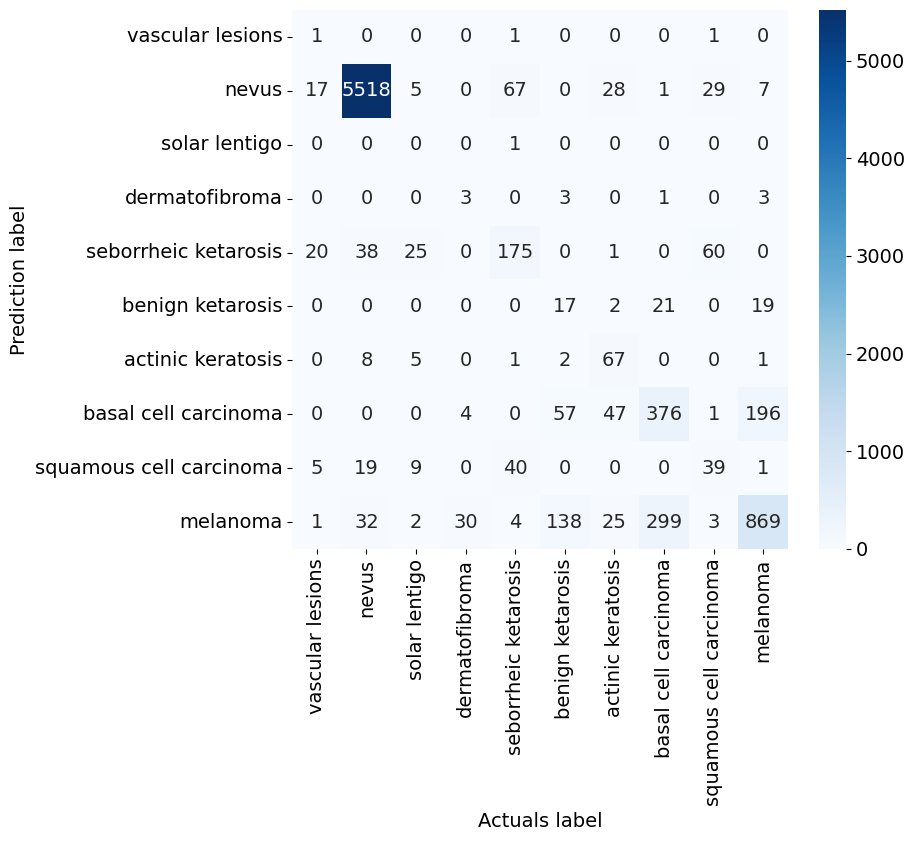

Sensitivity: 0.8466
Specificity: 0.9830
Precision: 0.8466
NPV: 0.9830
PPV: 0.8466
FNR: 0.1534
FPR: 0.0170
F1: 0.8466
Recall micro: 0.8466
Recall macro: 0.3789
Precision micro: 0.8466
Precision macro: 0.4757
F1 score micro: 0.8466
F1 score macro: 0.3932
Jaccard score micro: 0.7340
Jaccard score macro: 0.2971
Accuracy score: 0.8466
Matthews corrcoef: 0.7018
Specificity macro: 0.9795
Specificity micro: 0.9830
Specificity weighted: 0.9481
Specificity none - class vascular lesions (0): 0.9998
Specificity none - class nevus (1): 0.9436
Specificity none - class solar lentigo (2): 0.9999
Specificity none - class dermatofibroma (3): 0.9992
Specificity none - class seborrheic ketarosis (4): 0.9821
Specificity none - class benign ketarosis (5): 0.9948
Specificity none - class actinic keratosis (6): 0.9979
Specificity none - class basal cell carcinoma (7): 0.9601
Specificity none - class squamous cell carcinoma (8): 0.9910
Specificity none - class melanoma (9): 0.9263


In [21]:
actuals = []
predictions = []

test_NN(NET_deep, valloader)

torch.save(actuals, 'inception_v4\\actuals.pt')
torch.save(predictions, 'inception_v4\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'inception_v4\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.965133



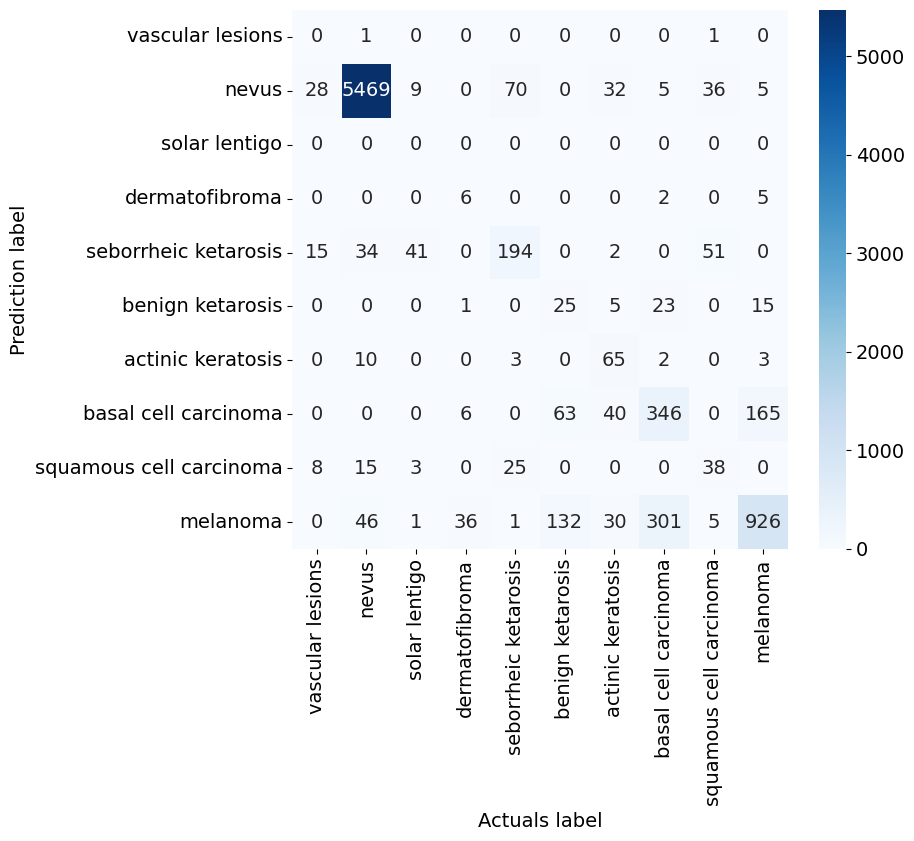

Sensitivity: 0.8471
Specificity: 0.9830
Precision: 0.8471
NPV: 0.9830
PPV: 0.8471
FNR: 0.1529
FPR: 0.0170
F1: 0.8471
Recall micro: 0.8471
Recall macro: 0.3880
Precision micro: 0.8471
Precision macro: 0.4761
F1 score micro: 0.8471
F1 score macro: 0.4054
Jaccard score micro: 0.7347
Jaccard score macro: 0.3061
Accuracy score: 0.8471
Matthews corrcoef: 0.7054
Specificity macro: 0.9788
Specificity micro: 0.9830
Specificity weighted: 0.9413
Specificity none - class vascular lesions (0): 0.9998
Specificity none - class nevus (1): 0.9332
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 0.9992
Specificity none - class seborrheic ketarosis (4): 0.9822
Specificity none - class benign ketarosis (5): 0.9946
Specificity none - class actinic keratosis (6): 0.9978
Specificity none - class basal cell carcinoma (7): 0.9643
Specificity none - class squamous cell carcinoma (8): 0.9938
Specificity none - class melanoma (9): 0.9236


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [22]:
actuals = []
predictions = []

test_NN(NET_deep, testloader)

torch.save(actuals, 'inception_v4\\actuals2.pt')
torch.save(predictions, 'inception_v4\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'inception_v4\\matrix2.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.161474



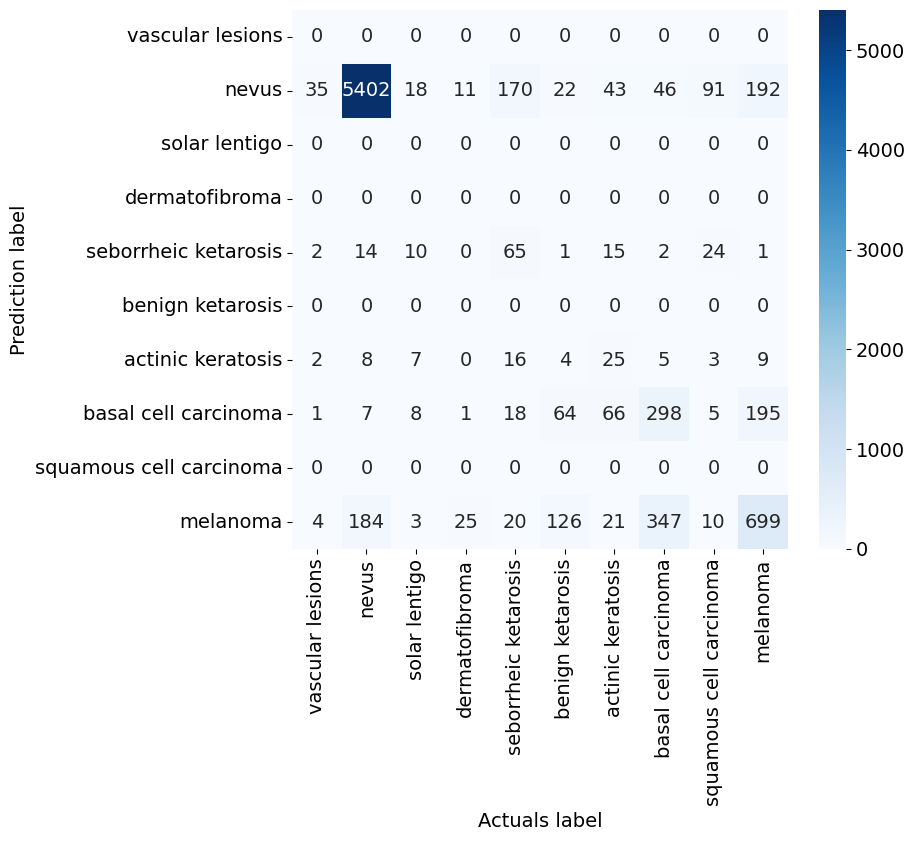

Sensitivity: 0.7776
Specificity: 0.9753
Precision: 0.7776
NPV: 0.9753
PPV: 0.7776
FNR: 0.2224
FPR: 0.0247
F1: 0.7776
Recall micro: 0.7776
Recall macro: 0.2399
Precision micro: 0.7776
Precision macro: 0.2633
F1 score micro: 0.7776
F1 score macro: 0.2425
Jaccard score micro: 0.6361
Jaccard score macro: 0.1820
Accuracy score: 0.7776
Matthews corrcoef: 0.5453
Specificity macro: 0.9605
Specificity micro: 0.9753
Specificity weighted: 0.8274
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7700
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9914
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9934
Specificity none - class basal cell carcinoma (7): 0.9523
Specificity none - class squamous cell carcinoma (8): 1.0000
Specificity none - class melanoma (9): 0.8979


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [23]:
actuals = []
predictions = []

model_name = 'NET_light.pt'
model_weights = torch.load(model_name, device)
nn_light.load_state_dict(model_weights)
NET_light = nn_light.to(device)

test_NN(NET_light, valloader)

torch.save(actuals, 'NET_light\\actuals.pt')
torch.save(predictions, 'NET_light\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.231427



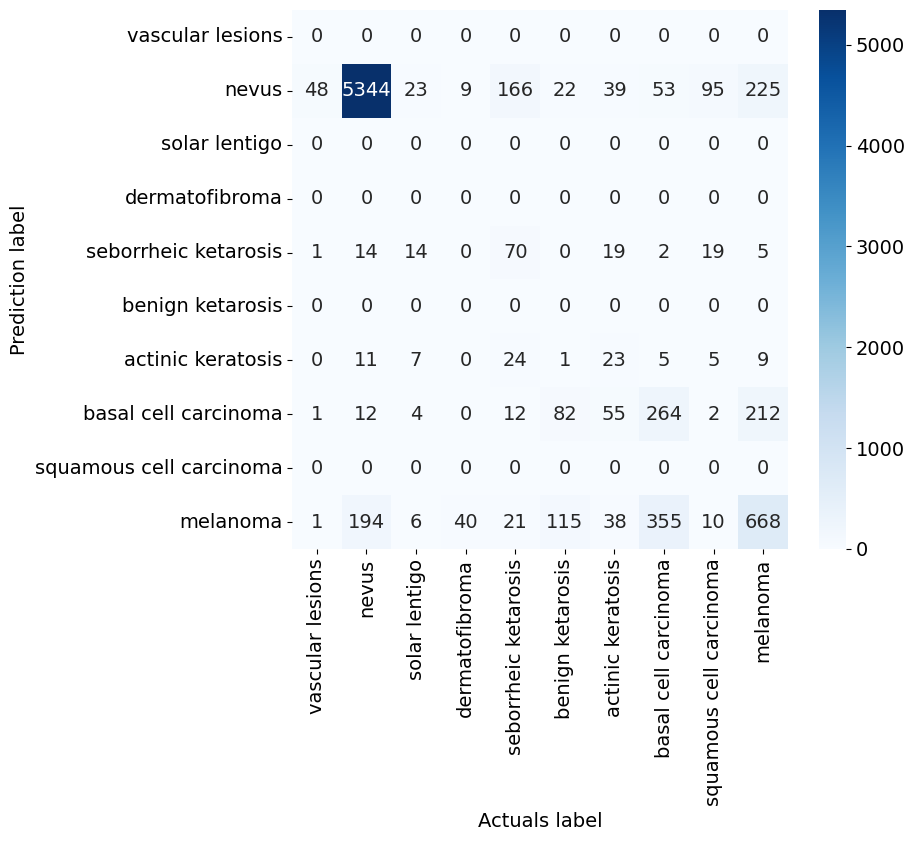

Sensitivity: 0.7632
Specificity: 0.9737
Precision: 0.7632
NPV: 0.9737
PPV: 0.7632
FNR: 0.2368
FPR: 0.0263
F1: 0.7632
Recall micro: 0.7632
Recall macro: 0.2315
Precision micro: 0.7632
Precision macro: 0.2515
F1 score micro: 0.7632
F1 score macro: 0.2339
Jaccard score micro: 0.6171
Jaccard score macro: 0.1744
Accuracy score: 0.7632
Matthews corrcoef: 0.5193
Specificity macro: 0.9580
Specificity micro: 0.9737
Specificity weighted: 0.8170
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7545
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9908
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9924
Specificity none - class basal cell carcinoma (7): 0.9504
Specificity none - class squamous cell carcinoma (8): 1.0000
Specificity none - class melanoma (9): 0.8921


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [24]:
actuals = []
predictions = []

test_NN(NET_light, testloader)

torch.save(actuals, 'NET_light\\actuals2.pt')
torch.save(predictions, 'NET_light\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'NET_light\\matrix2.pt')

test_metric()

In [25]:
def loss_kd(outputs, labels, teacher_outputs, temparature, alpha):
    
    KD_loss = nn.KLDivLoss(reduction='batchmean')(F.log_softmax(outputs/temparature, dim=1), F.softmax(teacher_outputs/temparature,dim=1)) * (alpha * temparature * temparature) + F.cross_entropy(outputs, labels) * (1. - alpha)
    
    return KD_loss

def get_outputs(model, dataloader):
    outputs = []
    
    for inputs, feats, labels, name in dataloader:
        inputs_batch, feats_batch, labels_batch = inputs.cuda(), feats.cuda(), labels.cuda()
        output_batch = model(inputs_batch, feats_batch).data.cpu().numpy()
        outputs.append(output_batch)
       
    return outputs

In [26]:
import torch.nn.functional as F

def train_kd(model, teacher_out, optimizer, loss_kd, dataloader, temparature, alpha):
    
    model.train()
    start_time_tarin = time.time()
    
    running_loss = 0.0
    running_corrects = 0
    
    for i, data in enumerate(dataloader):
        inputs, feats, labels, name = data
        inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(inputs, feats)
        outputs_teacher = torch.from_numpy(teacher_out[i]).to(device)
        
        loss = loss_kd(outputs, labels, outputs_teacher, temparature, alpha)
        _, preds = torch.max(outputs, 1)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)
   
    epoch_loss = running_loss / len_trainset
    epoch_acc = running_corrects.double() / len_trainset
    time_tarin = time.time()-start_time_tarin
    
    print('   Тренировочная ошибка: {:.4f} Точность: {:.4f}'.format(epoch_loss, epoch_acc))
    print ('        Время обучения: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_tarin))))
    
def eval_kd(model,teacher_out, optimizer, loss_kd, dataloader, temparature, alpha):
    
    model.eval()
    start_time_test = time.time()
    
    running_loss = 0.0
    running_corrects = 0
    
    for i, data in enumerate(dataloader):
        inputs, feats, labels, name = data
        inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
        
        outputs = model(inputs, feats)
        outputs_teacher = torch.from_numpy(teacher_out[i]).cuda()
        
        loss = loss_kd(outputs,labels,outputs_teacher,temparature, alpha)
        _, preds = torch.max(outputs, 1)
        
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)
        
    epoch_loss = running_loss / len_valset
    epoch_acc = running_corrects.double() / len_valset

    time_test = time.time()-start_time_test
    
    print('   Валидационная ошибка: {:.4f} Точность: {:.4f}'.format(epoch_loss, epoch_acc))
    print ('        Время тестирования: {}\n'.format(time.strftime("%H:%M:%S", time.gmtime(time_test))))
    
    return epoch_acc


def train_and_evaluate_kd(model, teacher_model, optimizer, loss_kd, trainloader, valloader, temparature, alpha, num_epochs=20):

    teacher_model.eval()
    start_time_glob = time.time()
    start_time_teacher_model = time.time()
    
    print('Процесс вывода весов с архитектуры-учителя...')
    
    best_model_wts = copy.deepcopy(model.state_dict())
    outputs_teacher_train = get_outputs(teacher_model, trainloader)
    outputs_teacher_val = get_outputs(teacher_model, valloader)

    time_teacher_model = time.time()-start_time_teacher_model
    print ('Время вывода весов с архитектуры-учителя: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_teacher_model))))
    
    best_acc = 0.0
    
    for epoch in range(num_epochs):

        print('_' * 60)
        print('Эпоха {}/{}'.format(epoch+1, num_epochs))
        
        train_kd(model, outputs_teacher_train, optimizer, loss_kd, trainloader, temparature, alpha)
        epoch_acc_val = eval_kd(model, outputs_teacher_val, optimizer, loss_kd, valloader, temparature, alpha)

        torch.save(model.state_dict(), f"student_epoch-{epoch+1}.pth")
        
        if epoch_acc_val > best_acc:
            best_acc = epoch_acc_val
            best_model_wts = copy.deepcopy(model.state_dict())
            
            torch.save(model.state_dict(), f"BestModel_student.pth")
            
        model.load_state_dict(best_model_wts)
            
        print('Лучшая валидационная точность: {:.4f}'.format(best_acc))
        
    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('\nОбщее время обучения: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    
    return model

In [27]:
optimizer = torch.optim.SGD(new_nn_light.parameters(), lr=0.001, momentum=0.9)

STUD_Model_1 = train_and_evaluate_kd (new_nn_light, NET_deep, optimizer, loss_kd, trainloader, valloader, 1, 0.5, 20)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:42
____________________________________________________________
Эпоха 1/20
   Тренировочная ошибка: 0.6880 Точность: 0.7362
        Время обучения: 00:01:02
   Валидационная ошибка: 0.6151 Точность: 0.7547
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7547
____________________________________________________________
Эпоха 2/20
   Тренировочная ошибка: 0.6146 Точность: 0.7516
        Время обучения: 00:01:02
   Валидационная ошибка: 0.5791 Точность: 0.7703
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7703
____________________________________________________________
Эпоха 3/20
   Тренировочная ошибка: 0.5814 Точность: 0.7606
        Время обучения: 00:01:02
   Валидационная ошибка: 0.5446 Точность: 0.7740
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7740
____________________________________________________________
Эпоха

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.868135



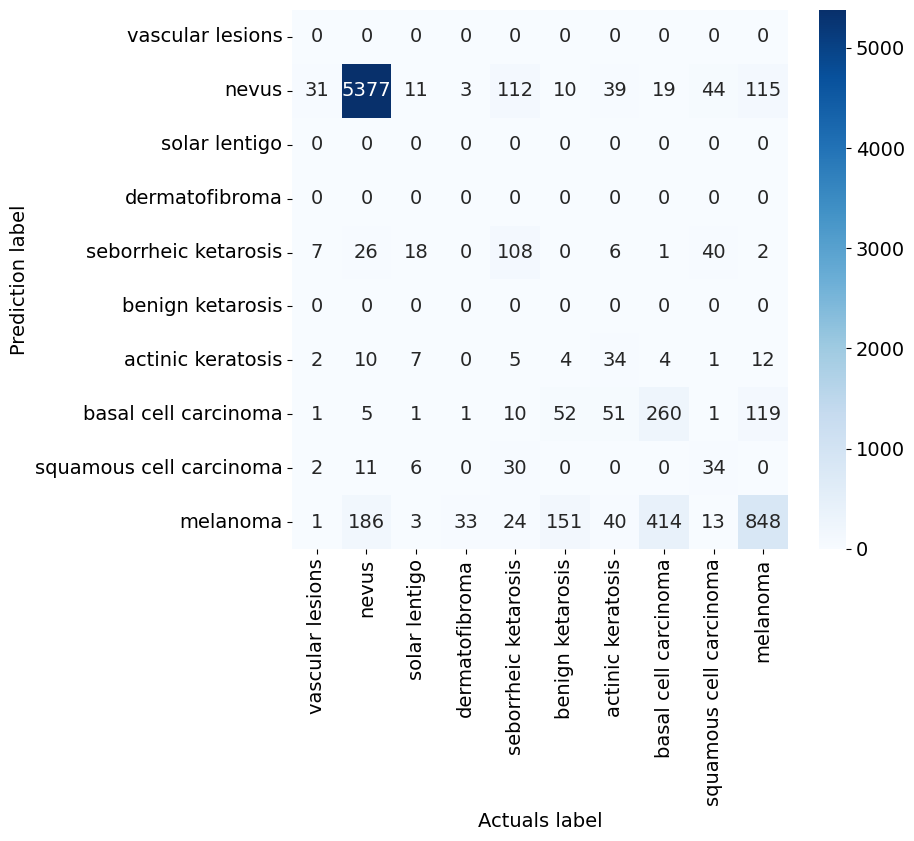

Sensitivity: 0.7982
Specificity: 0.9776
Precision: 0.7982
NPV: 0.9776
PPV: 0.7982
FNR: 0.2018
FPR: 0.0224
F1: 0.7982
Recall micro: 0.7982
Recall macro: 0.2933
Precision micro: 0.7982
Precision macro: 0.3307
F1 score micro: 0.7982
F1 score macro: 0.3005
Jaccard score micro: 0.6642
Jaccard score macro: 0.2228
Accuracy score: 0.7982
Matthews corrcoef: 0.6032
Specificity macro: 0.9685
Specificity micro: 0.9776
Specificity weighted: 0.8864
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8593
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9876
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9945
Specificity none - class basal cell carcinoma (7): 0.9685
Specificity none - class squamous cell carcinoma (8): 0.9940
Specificity none - class melanoma (9): 0.8807


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [41]:
actuals = []
predictions = []

test_NN(STUD_Model_1, valloader)

torch.save(actuals, 'STUD_Model_1\\actuals.pt')
torch.save(predictions, 'STUD_Model_1\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_1\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.999413



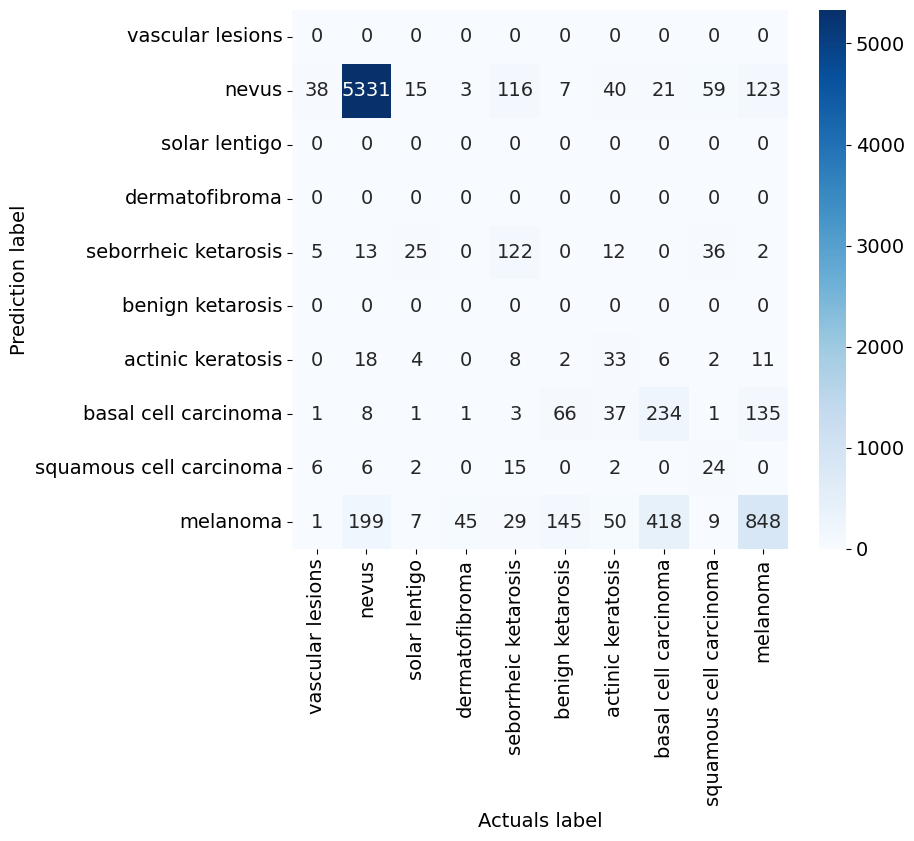

Sensitivity: 0.7899
Specificity: 0.9767
Precision: 0.7899
NPV: 0.9767
PPV: 0.7899
FNR: 0.2101
FPR: 0.0233
F1: 0.7899
Recall micro: 0.7899
Recall macro: 0.2848
Precision micro: 0.7899
Precision macro: 0.3288
F1 score micro: 0.7899
F1 score macro: 0.2928
Jaccard score micro: 0.6528
Jaccard score macro: 0.2170
Accuracy score: 0.7899
Matthews corrcoef: 0.5896
Specificity macro: 0.9668
Specificity micro: 0.9767
Specificity weighted: 0.8782
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8477
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9885
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9938
Specificity none - class basal cell carcinoma (7): 0.9670
Specificity none - class squamous cell carcinoma (8): 0.9962
Specificity none - class melanoma (9): 0.8750


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [31]:
actuals = []
predictions = []

test_NN(STUD_Model_1, testloader)

torch.save(actuals, 'STUD_Model_1\\actuals2.pt')
torch.save(predictions, 'STUD_Model_1\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_1\\matrix2.pt')

test_metric()

In [37]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_2 = MultimodalNN_light().to(device)

In [38]:
optimizer = torch.optim.SGD(new_nn_light_2.parameters(), lr=0.001, momentum=0.9)

STUD_Model_2 = train_and_evaluate_kd (new_nn_light_2, NET_deep, optimizer, loss_kd, trainloader, valloader, 2, 0.5, 20)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:43
____________________________________________________________
Эпоха 1/20
   Тренировочная ошибка: 2.1983 Точность: 0.6212
        Время обучения: 00:01:02
   Валидационная ошибка: 1.4052 Точность: 0.7051
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7051
____________________________________________________________
Эпоха 2/20
   Тренировочная ошибка: 1.4093 Точность: 0.7048
        Время обучения: 00:01:02
   Валидационная ошибка: 1.3423 Точность: 0.7166
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7166
____________________________________________________________
Эпоха 3/20
   Тренировочная ошибка: 1.3589 Точность: 0.7147
        Время обучения: 00:01:02
   Валидационная ошибка: 1.2941 Точность: 0.7223
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7223
____________________________________________________________
Эпоха

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.806696



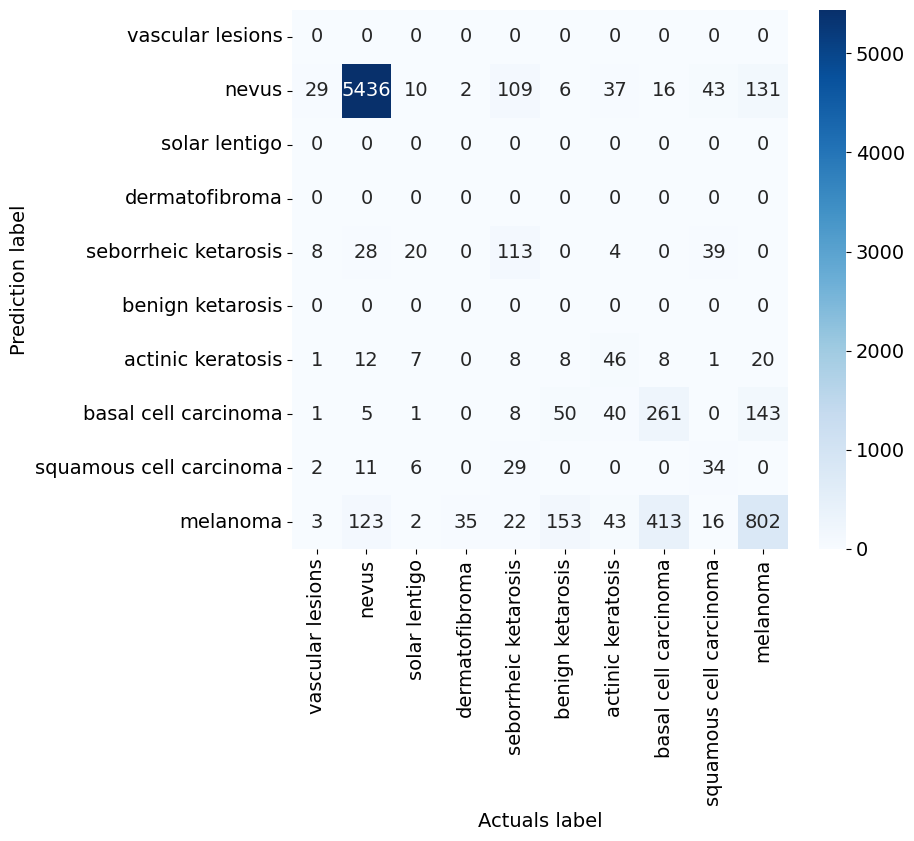

Sensitivity: 0.8019
Specificity: 0.9780
Precision: 0.8019
NPV: 0.9780
PPV: 0.8019
FNR: 0.1981
FPR: 0.0220
F1: 0.8019
Recall micro: 0.8019
Recall macro: 0.2991
Precision micro: 0.8019
Precision macro: 0.3307
F1 score micro: 0.8019
F1 score macro: 0.3070
Jaccard score micro: 0.6693
Jaccard score macro: 0.2278
Accuracy score: 0.8019
Matthews corrcoef: 0.6074
Specificity macro: 0.9689
Specificity micro: 0.9780
Specificity weighted: 0.8875
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8597
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9877
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9920
Specificity none - class basal cell carcinoma (7): 0.9676
Specificity none - class squamous cell carcinoma (8): 0.9942
Specificity none - class melanoma (9): 0.8883


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [42]:
actuals = []
predictions = []

test_NN(STUD_Model_2, valloader)

torch.save(actuals, 'STUD_Model_2\\actuals.pt')
torch.save(predictions, 'STUD_Model_2\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_2\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.895617



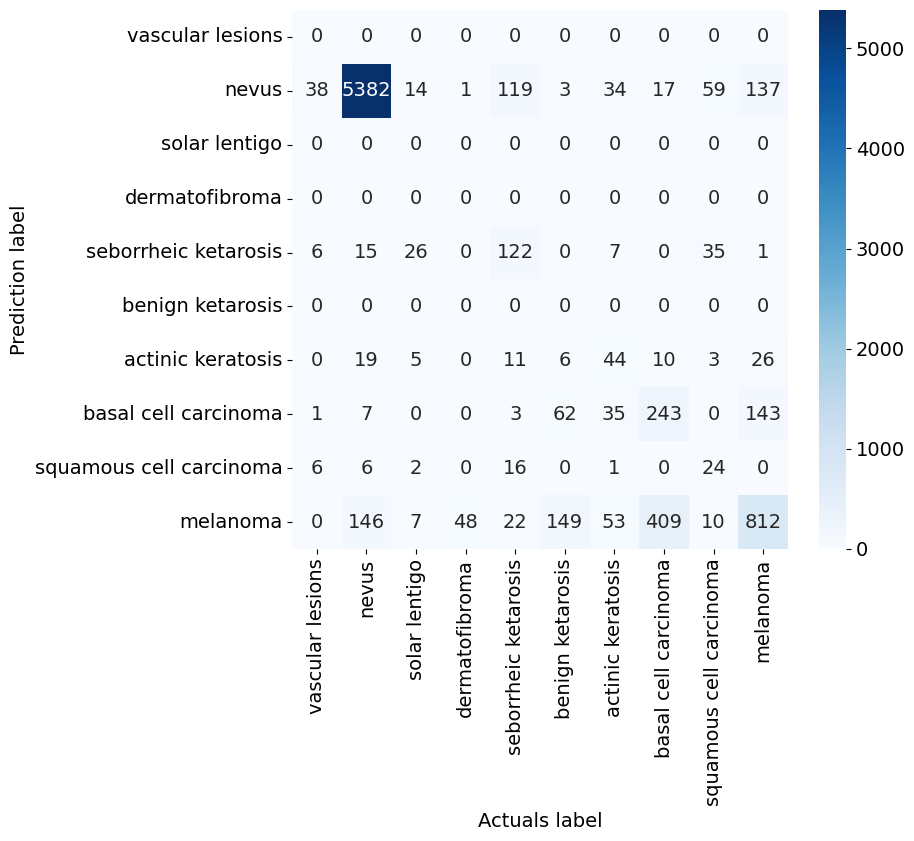

Sensitivity: 0.7941
Specificity: 0.9771
Precision: 0.7941
NPV: 0.9771
PPV: 0.7941
FNR: 0.2059
FPR: 0.0229
F1: 0.7941
Recall micro: 0.7941
Recall macro: 0.2901
Precision micro: 0.7941
Precision macro: 0.3276
F1 score micro: 0.7941
F1 score macro: 0.2982
Jaccard score micro: 0.6586
Jaccard score macro: 0.2212
Accuracy score: 0.7941
Matthews corrcoef: 0.5951
Specificity macro: 0.9673
Specificity micro: 0.9771
Specificity weighted: 0.8792
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8477
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9888
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9902
Specificity none - class basal cell carcinoma (7): 0.9673
Specificity none - class squamous cell carcinoma (8): 0.9962
Specificity none - class melanoma (9): 0.8832


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [39]:
actuals = []
predictions = []

test_NN(STUD_Model_2, testloader)

torch.save(actuals, 'STUD_Model_2\\actuals2.pt')
torch.save(predictions, 'STUD_Model_2\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_2\\matrix2.pt')

test_metric()

In [43]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_3 = MultimodalNN_light().to(device)

In [44]:
optimizer = torch.optim.SGD(new_nn_light_3.parameters(), lr=0.001, momentum=0.9)

STUD_Model_3 = train_and_evaluate_kd (new_nn_light_3, NET_deep, optimizer, loss_kd, trainloader, valloader, 5, 0.5, 20)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:43
____________________________________________________________
Эпоха 1/20
   Тренировочная ошибка: 4.6568 Точность: 0.6352
        Время обучения: 00:01:02
   Валидационная ошибка: 3.2210 Точность: 0.7135
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7135
____________________________________________________________
Эпоха 2/20
   Тренировочная ошибка: 3.1921 Точность: 0.7111
        Время обучения: 00:01:02
   Валидационная ошибка: 3.0000 Точность: 0.7274
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7274
____________________________________________________________
Эпоха 3/20
   Тренировочная ошибка: 2.9918 Точность: 0.7267
        Время обучения: 00:01:02
   Валидационная ошибка: 2.8212 Точность: 0.7452
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7452
____________________________________________________________
Эпоха

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.823580



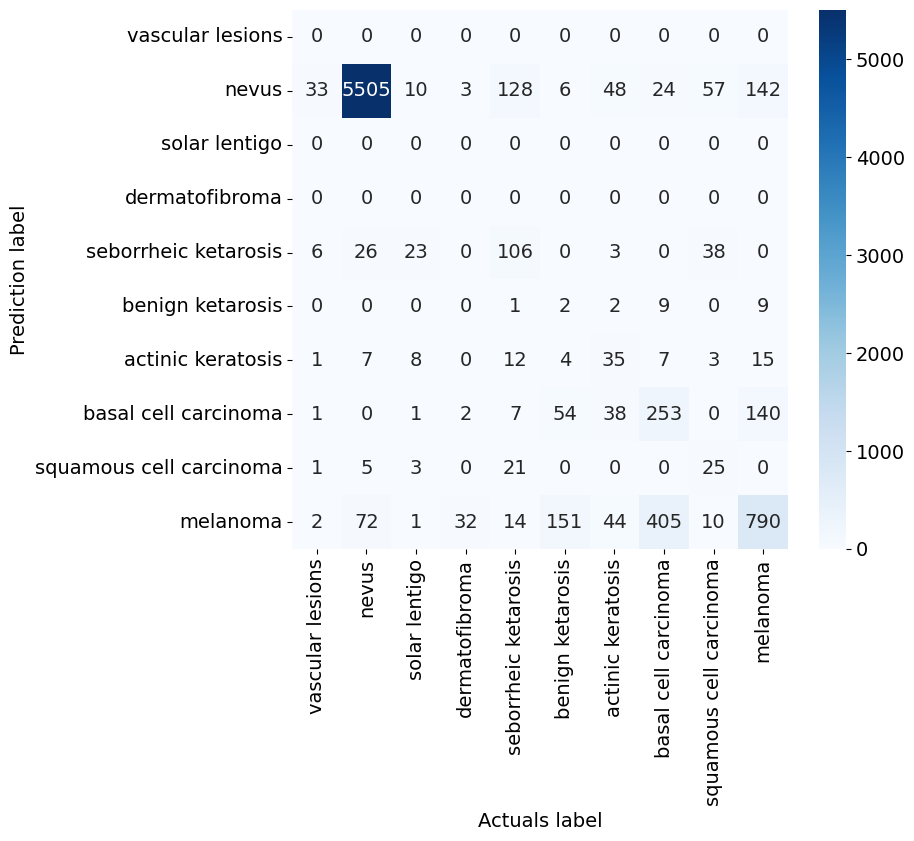

Sensitivity: 0.8048
Specificity: 0.9783
Precision: 0.8048
NPV: 0.9783
PPV: 0.8048
FNR: 0.1952
FPR: 0.0217
F1: 0.8048
Recall micro: 0.8048
Recall macro: 0.2834
Precision micro: 0.8048
Precision macro: 0.3400
F1 score micro: 0.8048
F1 score macro: 0.2961
Jaccard score micro: 0.6734
Jaccard score macro: 0.2200
Accuracy score: 0.8048
Matthews corrcoef: 0.6063
Specificity macro: 0.9677
Specificity micro: 0.9783
Specificity weighted: 0.8723
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8348
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9881
Specificity none - class benign ketarosis (5): 0.9974
Specificity none - class actinic keratosis (6): 0.9930
Specificity none - class basal cell carcinoma (7): 0.9682
Specificity none - class squamous cell carcinoma (8): 0.9963
Specificity none - class melanoma (9): 0.8992


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [45]:
actuals = []
predictions = []

test_NN(STUD_Model_3, valloader)

torch.save(actuals, 'STUD_Model_3\\actuals.pt')
torch.save(predictions, 'STUD_Model_3\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_3\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.060279



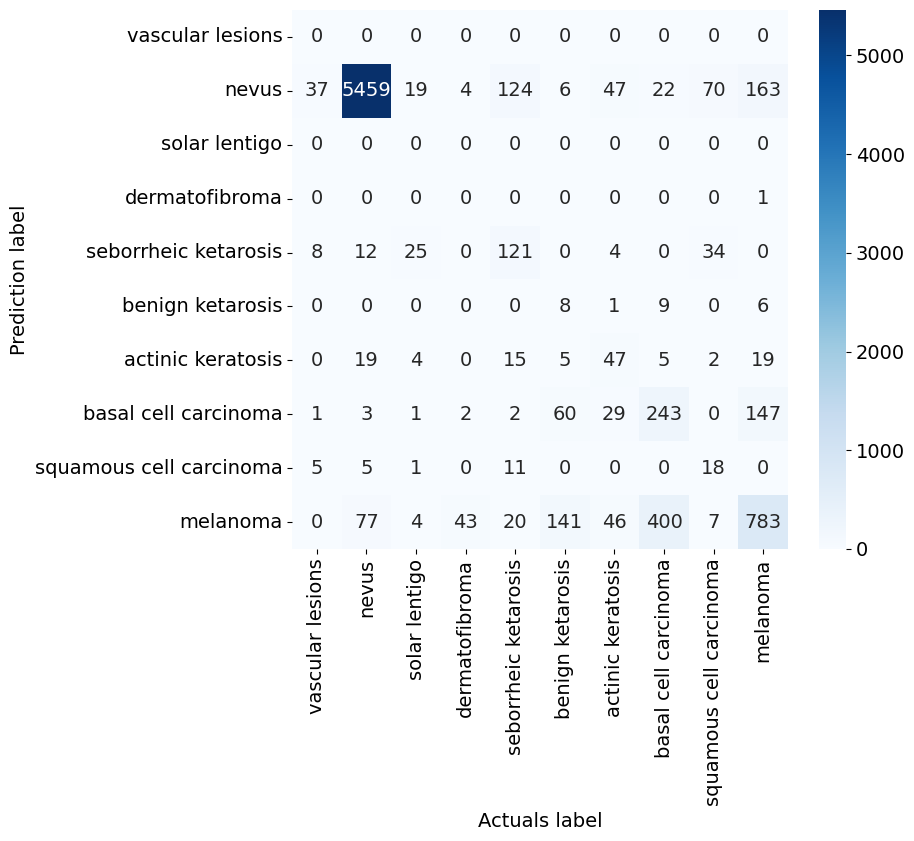

Sensitivity: 0.8004
Specificity: 0.9778
Precision: 0.8004
NPV: 0.9778
PPV: 0.8004
FNR: 0.1996
FPR: 0.0222
F1: 0.8004
Recall micro: 0.8004
Recall macro: 0.2894
Precision micro: 0.8004
Precision macro: 0.3712
F1 score micro: 0.8004
F1 score macro: 0.3044
Jaccard score micro: 0.6672
Jaccard score macro: 0.2251
Accuracy score: 0.8004
Matthews corrcoef: 0.6003
Specificity macro: 0.9665
Specificity micro: 0.9778
Specificity weighted: 0.8644
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8224
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 0.9999
Specificity none - class seborrheic ketarosis (4): 0.9897
Specificity none - class benign ketarosis (5): 0.9980
Specificity none - class actinic keratosis (6): 0.9916
Specificity none - class basal cell carcinoma (7): 0.9680
Specificity none - class squamous cell carcinoma (8): 0.9973
Specificity none - class melanoma (9): 0.8979


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [46]:
actuals = []
predictions = []

test_NN(STUD_Model_3, testloader)

torch.save(actuals, 'STUD_Model_3\\actuals2.pt')
torch.save(predictions, 'STUD_Model_3\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_3\\matrix2.pt')

test_metric()

In [47]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_4 = MultimodalNN_light().to(device)

In [48]:
optimizer = torch.optim.SGD(new_nn_light_4.parameters(), lr=0.001, momentum=0.9)

STUD_Model_4 = train_and_evaluate_kd (new_nn_light_4, NET_deep, optimizer, loss_kd, trainloader, valloader, 2, 0.25, 25)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:42
____________________________________________________________
Эпоха 1/25
   Тренировочная ошибка: 1.8521 Точность: 0.6143
        Время обучения: 00:01:02
   Валидационная ошибка: 1.1977 Точность: 0.7058
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7058
____________________________________________________________
Эпоха 2/25
   Тренировочная ошибка: 1.1848 Точность: 0.7051
        Время обучения: 00:01:02
   Валидационная ошибка: 1.1195 Точность: 0.7168
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7168
____________________________________________________________
Эпоха 3/25
   Тренировочная ошибка: 1.1405 Точность: 0.7134
        Время обучения: 00:01:02
   Валидационная ошибка: 1.0873 Точность: 0.7233
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7233
____________________________________________________________
Эпоха

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.827518



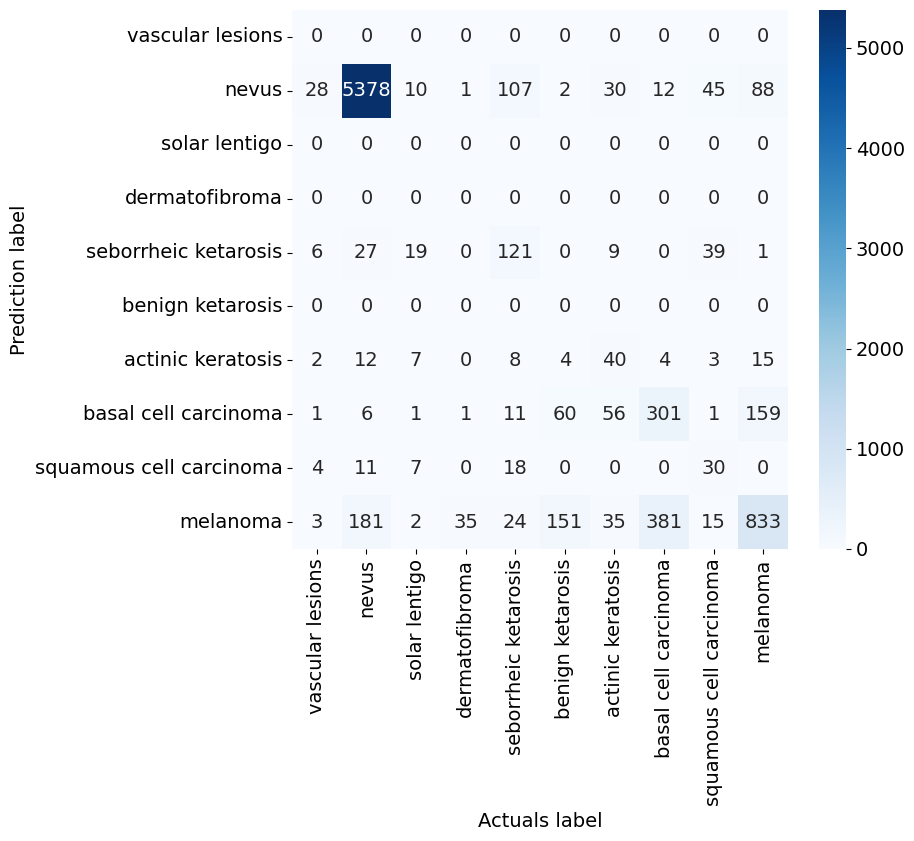

Sensitivity: 0.8032
Specificity: 0.9781
Precision: 0.8032
NPV: 0.9781
PPV: 0.8032
FNR: 0.1968
FPR: 0.0219
F1: 0.8032
Recall micro: 0.8032
Recall macro: 0.3029
Precision micro: 0.8032
Precision macro: 0.3344
F1 score micro: 0.8032
F1 score macro: 0.3091
Jaccard score micro: 0.6712
Jaccard score macro: 0.2303
Accuracy score: 0.8032
Matthews corrcoef: 0.6157
Specificity macro: 0.9705
Specificity micro: 0.9781
Specificity weighted: 0.9015
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8817
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9875
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9933
Specificity none - class basal cell carcinoma (7): 0.9613
Specificity none - class squamous cell carcinoma (8): 0.9951
Specificity none - class melanoma (9): 0.8859


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [49]:
actuals = []
predictions = []

test_NN(STUD_Model_4, valloader)

torch.save(actuals, 'STUD_Model_4\\actuals.pt')
torch.save(predictions, 'STUD_Model_4\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_4\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.879303



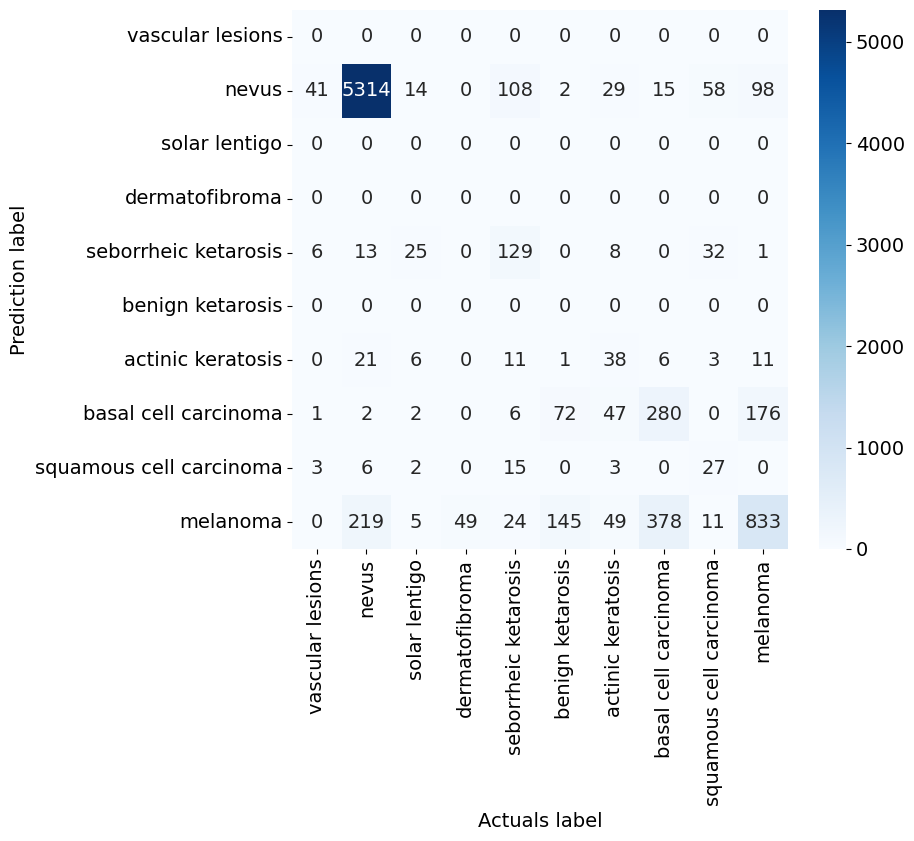

Sensitivity: 0.7934
Specificity: 0.9770
Precision: 0.7934
NPV: 0.9770
PPV: 0.7934
FNR: 0.2066
FPR: 0.0230
F1: 0.7934
Recall micro: 0.7934
Recall macro: 0.2975
Precision micro: 0.7934
Precision macro: 0.3377
F1 score micro: 0.7934
F1 score macro: 0.3053
Jaccard score micro: 0.6576
Jaccard score macro: 0.2269
Accuracy score: 0.7934
Matthews corrcoef: 0.5998
Specificity macro: 0.9685
Specificity micro: 0.9770
Specificity weighted: 0.8918
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8682
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9894
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9928
Specificity none - class basal cell carcinoma (7): 0.9601
Specificity none - class squamous cell carcinoma (8): 0.9965
Specificity none - class melanoma (9): 0.8782


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [50]:
actuals = []
predictions = []

test_NN(STUD_Model_4, testloader)

torch.save(actuals, 'STUD_Model_4\\actuals2.pt')
torch.save(predictions, 'STUD_Model_4\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_4\\matrix2.pt')

test_metric()

In [51]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

torch.manual_seed(42)
new_nn_light_5 = MultimodalNN_light().to(device)

In [52]:
optimizer = torch.optim.SGD(new_nn_light_5.parameters(), lr=0.001, momentum=0.9)

STUD_Model_5 = train_and_evaluate_kd (new_nn_light_5, NET_deep, optimizer, loss_kd, trainloader, valloader, 2, 0.75, 30)

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:42
____________________________________________________________
Эпоха 1/30
   Тренировочная ошибка: 2.5162 Точность: 0.6347
        Время обучения: 00:01:02
   Валидационная ошибка: 1.5935 Точность: 0.7046
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7046
____________________________________________________________
Эпоха 2/30
   Тренировочная ошибка: 1.6020 Точность: 0.7015
        Время обучения: 00:01:02
   Валидационная ошибка: 1.5269 Точность: 0.7125
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7125
____________________________________________________________
Эпоха 3/30
   Тренировочная ошибка: 1.5410 Точность: 0.7108
        Время обучения: 00:01:02
   Валидационная ошибка: 1.4656 Точность: 0.7228
        Время тестирования: 00:00:09

Лучшая валидационная точность: 0.7228
____________________________________________________________
Эпоха

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.760219



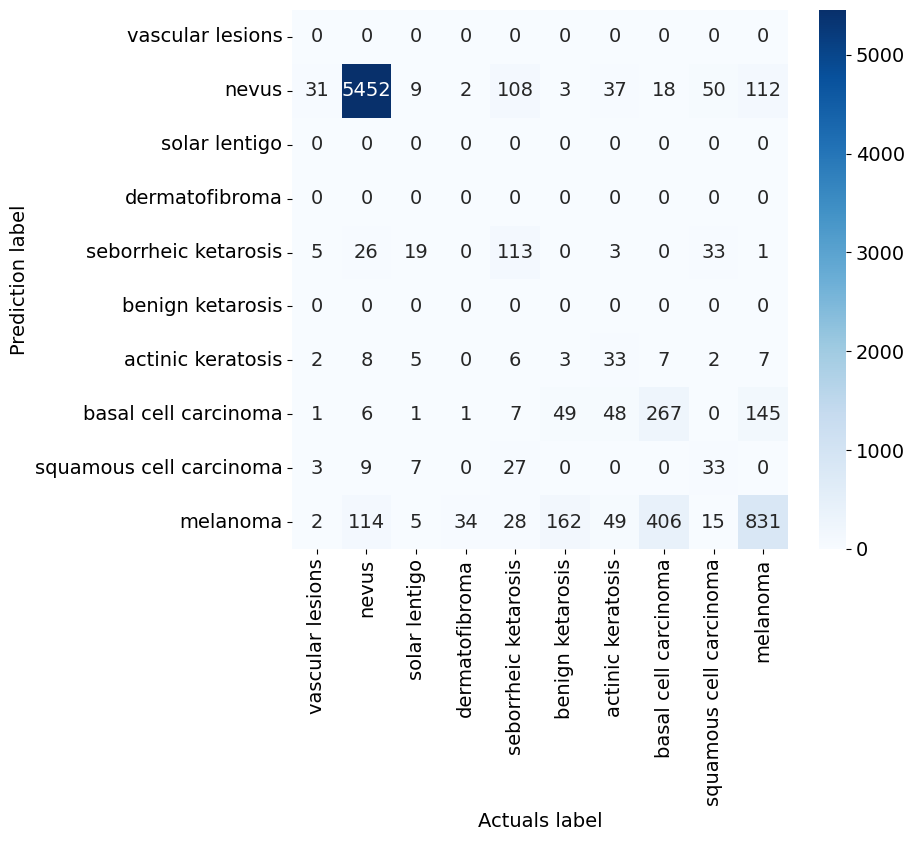

Sensitivity: 0.8064
Specificity: 0.9785
Precision: 0.8064
NPV: 0.9785
PPV: 0.8064
FNR: 0.1936
FPR: 0.0215
F1: 0.8064
Recall micro: 0.8064
Recall macro: 0.2945
Precision micro: 0.8064
Precision macro: 0.3385
F1 score micro: 0.8064
F1 score macro: 0.3041
Jaccard score micro: 0.6755
Jaccard score macro: 0.2267
Accuracy score: 0.8064
Matthews corrcoef: 0.6161
Specificity macro: 0.9697
Specificity micro: 0.9785
Specificity weighted: 0.8907
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8645
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9892
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9951
Specificity none - class basal cell carcinoma (7): 0.9663
Specificity none - class squamous cell carcinoma (8): 0.9944
Specificity none - class melanoma (9): 0.8876


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [53]:
actuals = []
predictions = []

test_NN(STUD_Model_5, valloader)

torch.save(actuals, 'STUD_Model_5\\actuals.pt')
torch.save(predictions, 'STUD_Model_5\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_5\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.493371



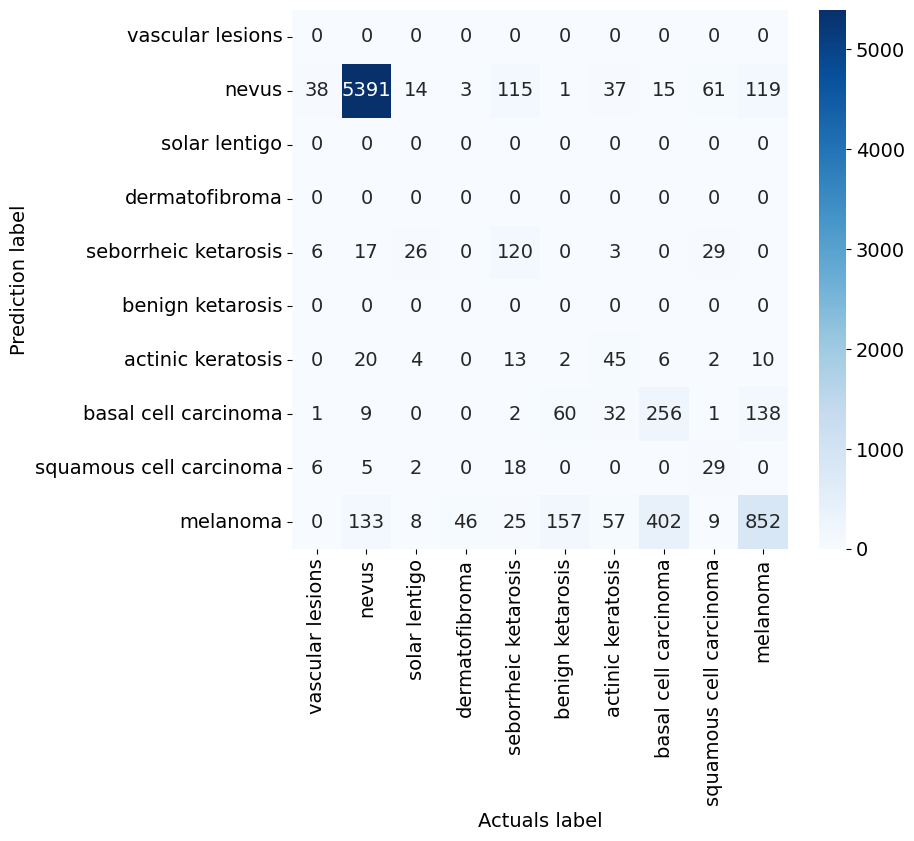

Sensitivity: 0.8020
Specificity: 0.9780
Precision: 0.8020
NPV: 0.9780
PPV: 0.8020
FNR: 0.1980
FPR: 0.0220
F1: 0.8020
Recall micro: 0.8020
Recall macro: 0.2995
Precision micro: 0.8020
Precision macro: 0.3469
F1 score micro: 0.8020
F1 score macro: 0.3105
Jaccard score micro: 0.6695
Jaccard score macro: 0.2310
Accuracy score: 0.8020
Matthews corrcoef: 0.6115
Specificity macro: 0.9686
Specificity micro: 0.9780
Specificity weighted: 0.8841
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8545
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9899
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9930
Specificity none - class basal cell carcinoma (7): 0.9683
Specificity none - class squamous cell carcinoma (8): 0.9962
Specificity none - class melanoma (9): 0.8842


C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [54]:
actuals = []
predictions = []

test_NN(STUD_Model_5, testloader)

torch.save(actuals, 'STUD_Model_5\\actuals2.pt')
torch.save(predictions, 'STUD_Model_5\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'STUD_Model_5\\matrix2.pt')

test_metric()

In [55]:
test_1 = test(NET_deep, valloader, device)
print(f"Точность модели-учителя: {test_1:.2f}%")

test_2 = test(NET_light, valloader, device)
print(f"Точность модели-ученика без учителя: {test_2:.2f}%")

test_3 = test(STUD_Model_1, valloader, device)
print(f"Точность модели-ученика со значениями Т=1, alpha=0.5: {test_3:.2f}%")

test_4 = test(STUD_Model_2, valloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.5: {test_4:.2f}%")

test_5 = test(STUD_Model_3, valloader, device)
print(f"Точность модели-ученика со значениями Т=5, alpha=0.5: {test_5:.2f}%")

test_6 = test(STUD_Model_4, valloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.25: {test_6:.2f}%")

test_7 = test(STUD_Model_5, valloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.75: {test_7:.2f}%")

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.709025

Точность модели-учителя: 84.66%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.816868

Точность модели-ученика без учителя: 79.27%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.814752

Точность модели-ученика со значениями Т=1, alpha=0.5: 79.82%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.860785

Точность модели-ученика со значениями Т=2, alpha=0.5: 80.19%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.846626

Точность модели-ученика со значениями Т=5, alpha=0.5: 80.48%
____________________________________________________________
Время тестирования: 00:0

In [ ]:
test_1 = test(NET_deep, testloader, device)
print(f"Точность модели-учителя: {test_1:.2f}%")

test_2 = test(NET_light, testloader, device)
print(f"Точность модели-ученика без учителя: {test_2:.2f}%")

test_3 = test(STUD_Model_1, testloader, device)
print(f"Точность модели-ученика со значениями Т=1, alpha=0.5: {test_3:.2f}%")

test_4 = test(STUD_Model_2, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.5: {test_4:.2f}%")

test_5 = test(STUD_Model_3, testloader, device)
print(f"Точность модели-ученика со значениями Т=5, alpha=0.5: {test_5:.2f}%")

test_6 = test(STUD_Model_4, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.25: {test_6:.2f}%")

test_7 = test(STUD_Model_5, testloader, device)
print(f"Точность модели-ученика со значениями Т=2, alpha=0.75: {test_7:.2f}%")

____________________________________________________________
Время тестирования: 00:00:10
Время тестирования в секундах: 10.767599

Точность модели-учителя: 84.71%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.859004

Точность модели-ученика без учителя: 78.17%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.842725

Точность модели-ученика со значениями Т=1, alpha=0.5: 78.99%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.828732

Точность модели-ученика со значениями Т=2, alpha=0.5: 79.41%
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.784384

Точность модели-ученика со значениями Т=5, alpha=0.5: 80.04%
____________________________________________________________
Время тестирования: 00:0